# Manuscript Layout Region Detection

In this notebook I go through my pipeline **one step at a time** so I can *see* what each step does.
The goal: find these regions on a manuscript page and give each a label + confidence:

`header`, `footer`, `main_text`, `side_text`, `filler`

I did not use a neural network because the assignment gives no labelled training data.
Instead I use classical image processing (OpenCV) plus simple layout rules.

**How to use:** run the cells from top to bottom (Kernel -> Restart & Run All).

## 0. Setup

In [34]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

# make sure we are standing in the project folder (the one that contains "src")
if not os.path.isdir("src"):
    os.chdir("..")
print("working folder:", os.getcwd())

from src.image_utils import read_image, resize_for_work, list_images
from src.preprocessing import make_gray, fix_lighting, find_page, make_ink_mask, find_ruling_lines
from src.line_finder import clean_ink, guess_char_height, split_edge_stamp_text, find_text_blobs
from src.pipeline import analyze_image, run_on_path
from src.visualize import draw_regions

def show(img, title="", gray=False, size=(12, 5)):
    # small helper so I don't repeat the matplotlib lines every time
    plt.figure(figsize=size)
    if gray or len(img.shape) == 2:
        plt.imshow(img, cmap="gray")
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))   # opencv is BGR, matplotlib wants RGB
    plt.title(title)
    plt.axis("off")
    plt.show()

working folder: C:\Users\ameys\manuscript_layout_detection\manuscript_layout_detection


## 1. Load an image
Pick any file from `data/test_images`. Change `IMAGE_NAME` to try the others.
(`synthetic_demo_page.png` is a fake page I made to test header / footer / side text, the other two are the real samples.)

image size (height, width, channels): (834, 2048, 3)


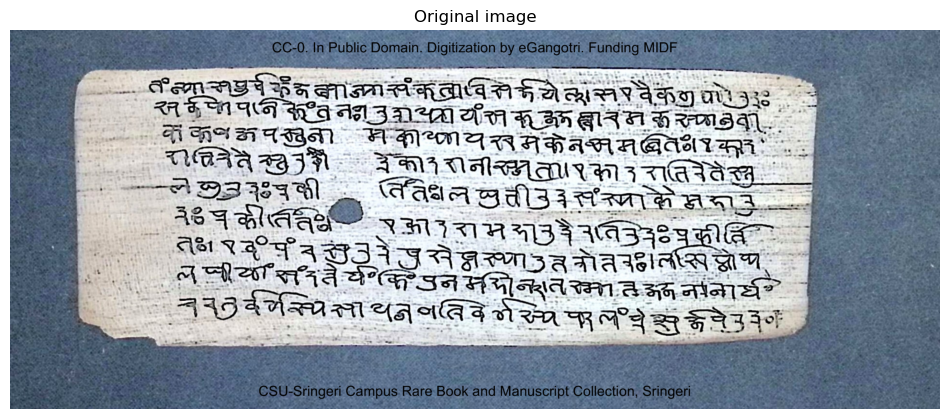

In [37]:
IMAGE_NAME = r"C:\Users\ameys\OneDrive\Pictures\manuscript1.png"

path = IMAGE_NAME
img = read_image(path)

print("image size (height, width, channels):", img.shape)
show(img, "Original image")

## 2. Shrink it, make it gray, fix the lighting
- big images are shrunk to 1600px wide so everything runs fast (boxes are scaled back at the end)
- colour doesn't help us, so we use gray
- `fix_lighting` divides the image by an estimate of the "empty page", so stains and shadows mostly cancel out and the ink stays dark

scale factor to get back to the original: 1.28


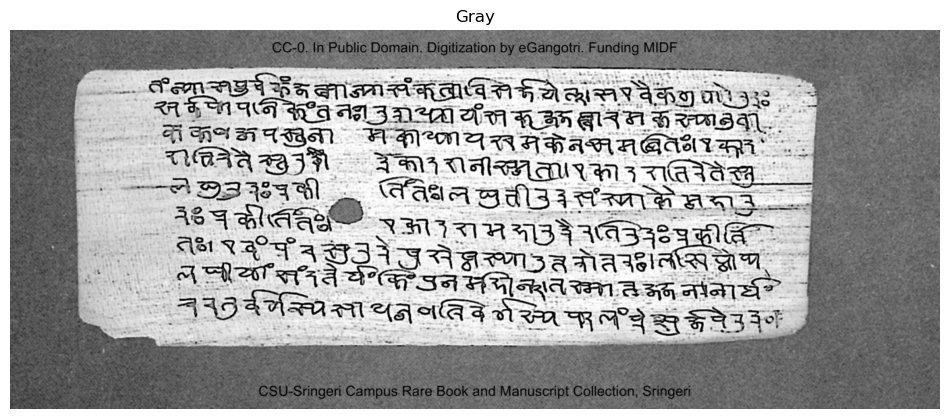

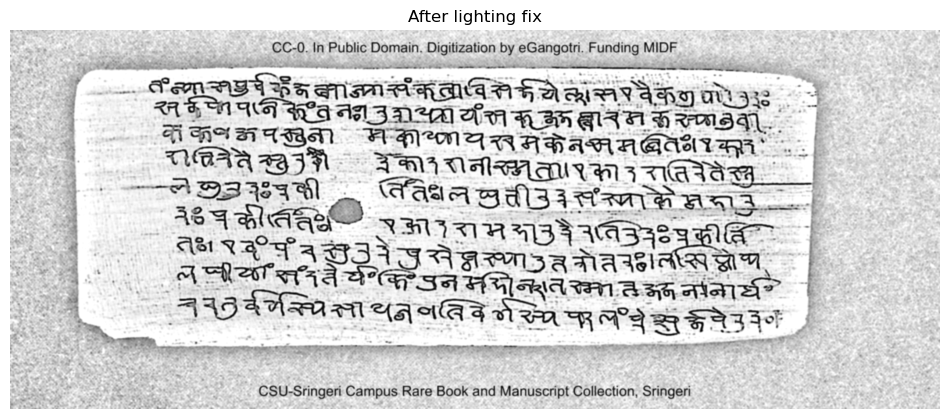

In [40]:
small, scale = resize_for_work(img)
gray = make_gray(small)
flat = fix_lighting(gray)
print("scale factor to get back to the original:", round(scale, 3))

show(gray, "Gray", gray=True)
show(flat, "After lighting fix", gray=True)

## 3. Find the page
Palm leaves are photographed on a coloured cloth, so first I find where the leaf is.
If the page fills the whole picture (like a scan) I just use the whole image.

page box: (112, 65, 1389, 545)


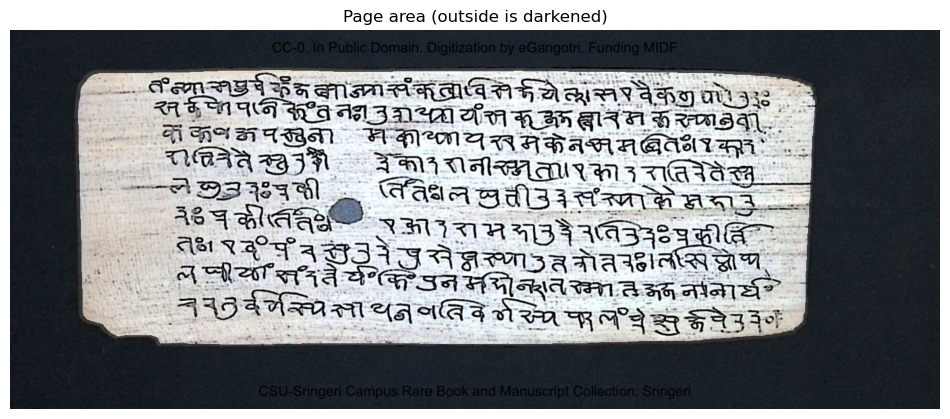

In [43]:
page_mask, page_box = find_page(gray)
print("page box:", page_box)

overlay = small.copy()
overlay[page_mask == 0] = (overlay[page_mask == 0] * 0.3).astype(np.uint8)   # darken everything outside
show(overlay, "Page area (outside is darkened)")

## 4. Ink mask and border lines
- `make_ink_mask` uses Otsu thresholding to make a black/white picture where white = ink
- `find_ruling_lines` finds long page borders so we don't treat them as writing

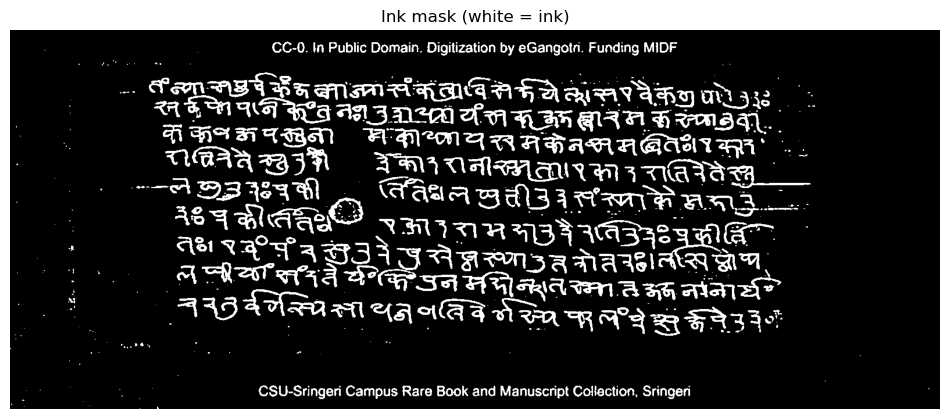

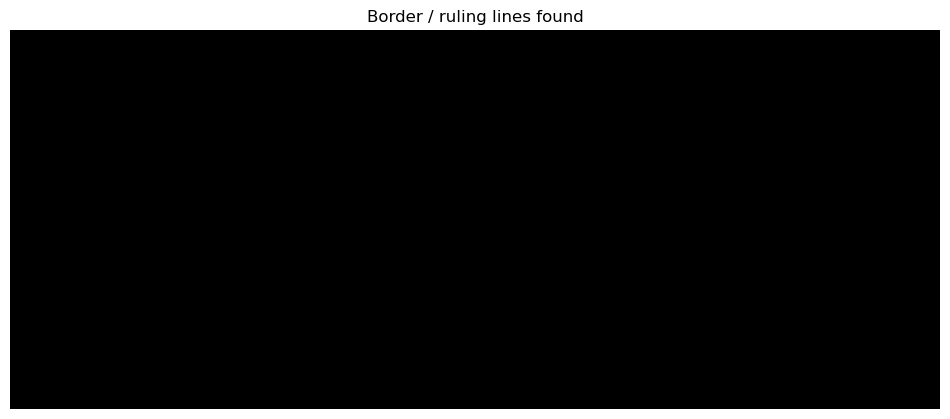

In [46]:
ink = make_ink_mask(flat, page_mask)
lines = find_ruling_lines(ink)

show(ink, "Ink mask (white = ink)", gray=True)
show(lines, "Border / ruling lines found", gray=True)

## 5. Clean the ink
Remove dust, leftover line pieces and big solid stains / holes, then guess how tall one character is
(so the code works for big and small handwriting).

guessed character height: 34 pixels


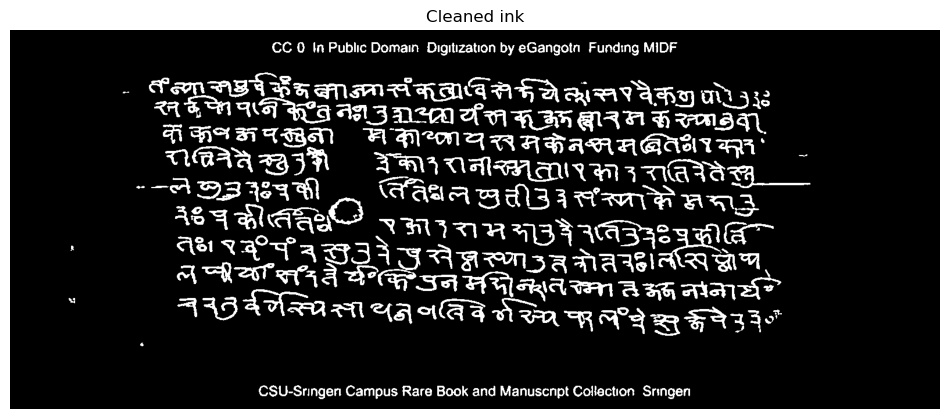

In [49]:
ink_without_lines = ink.copy()
ink_without_lines[lines > 0] = 0

cleaned = clean_ink(ink_without_lines)
char_h = guess_char_height(cleaned)
print("guessed character height:", char_h, "pixels")

show(cleaned, "Cleaned ink", gray=True)

## 6. Glue letters into blobs
Small stamp text (like the watermark) is set aside first so it can't get glued to the real writing.
Then I dilate the ink so letters that are close together merge into blobs (lines / paragraphs / page numbers).

number of blobs found: 3


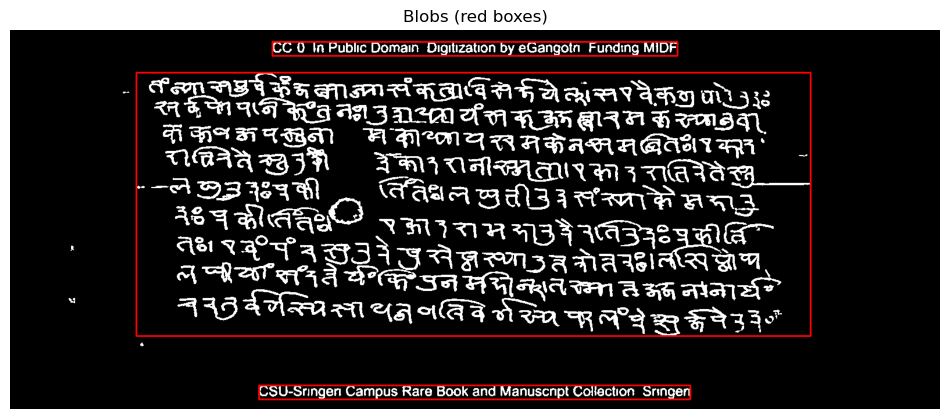

In [52]:
stamp_ink, body_ink = split_edge_stamp_text(cleaned, char_h)
blobs = find_text_blobs(body_ink, char_h) + find_text_blobs(stamp_ink, char_h)
print("number of blobs found:", len(blobs))

preview = cv2.cvtColor(cleaned, cv2.COLOR_GRAY2BGR)
for b in blobs:
    x1, y1, x2, y2 = b["box"]
    cv2.rectangle(preview, (x1, y1), (x2, y2), (0, 0, 255), 2)
show(preview, "Blobs (red boxes)")

## 7. Decide what each blob is
This is the job of `classifier.py`. The rules are (in order):
1. outside the page, or small centred stamp text at the top/bottom -> **filler**
2. the biggest blobs of ink -> **main_text**
3. left/right of the main text -> **side_text**
4. above the main text -> **header**
5. below the main text -> **footer**
6. anything else -> **filler** (low confidence)

`analyze_image` runs all the steps above in one go and gives back the final regions.

In [55]:
regions, page_box, steps = analyze_image(img)

for r in regions:
    print(f"{r['label']:10s} box={r['bbox']}  confidence={r['confidence']}")
    print(f"           why: {r['reason']}")

filler     box=[577, 26, 1469, 56]  confidence=0.9
           why: text lying outside the page (caption / stamp)
main_text  box=[278, 93, 1763, 673]  confidence=0.99
           why: one of the biggest blocks of writing on the page
filler     box=[548, 782, 1498, 813]  confidence=0.9
           why: text lying outside the page (caption / stamp)


## 8. Final picture

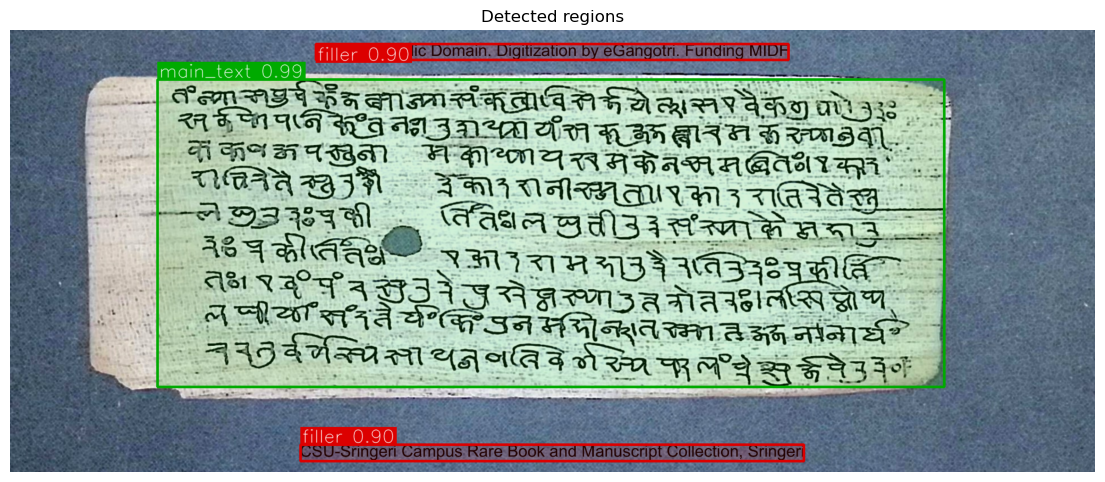

In [58]:
annotated = draw_regions(img, regions)
show(annotated, "Detected regions", size=(14, 6))

## 9. Run on the whole folder (same thing the command line does)
This writes an annotated image and a JSON file per page into `results/`.
The original images are never touched.

In [61]:
all_results = run_on_path(os.path.join("data", "test_images"), "results")

[1/3] sample_palm_leaf.png
   found: {'filler': 2, 'main_text': 1}
[2/3] sample_paper.png
   found: {'filler': 4, 'main_text': 1}
[3/3] synthetic_demo_page.png
   found: {'header': 1, 'main_text': 1, 'side_text': 5, 'footer': 2}
Done. Results are in results


In [62]:
# look at the JSON of the first page
print(json.dumps(all_results[0], indent=2)[:1500])

{
  "image": "sample_palm_leaf.png",
  "width": 2048,
  "height": 834,
  "page_box": [
    143,
    83,
    1778,
    698
  ],
  "regions": [
    {
      "label": "filler",
      "bbox": [
        577,
        26,
        1469,
        56
      ],
      "confidence": 0.9,
      "reason": "text lying outside the page (caption / stamp)"
    },
    {
      "label": "main_text",
      "bbox": [
        278,
        93,
        1763,
        673
      ],
      "confidence": 0.99,
      "reason": "one of the biggest blocks of writing on the page"
    },
    {
      "label": "filler",
      "bbox": [
        548,
        782,
        1498,
        813
      ],
      "confidence": 0.9,
      "reason": "text lying outside the page (caption / stamp)"
    }
  ]
}


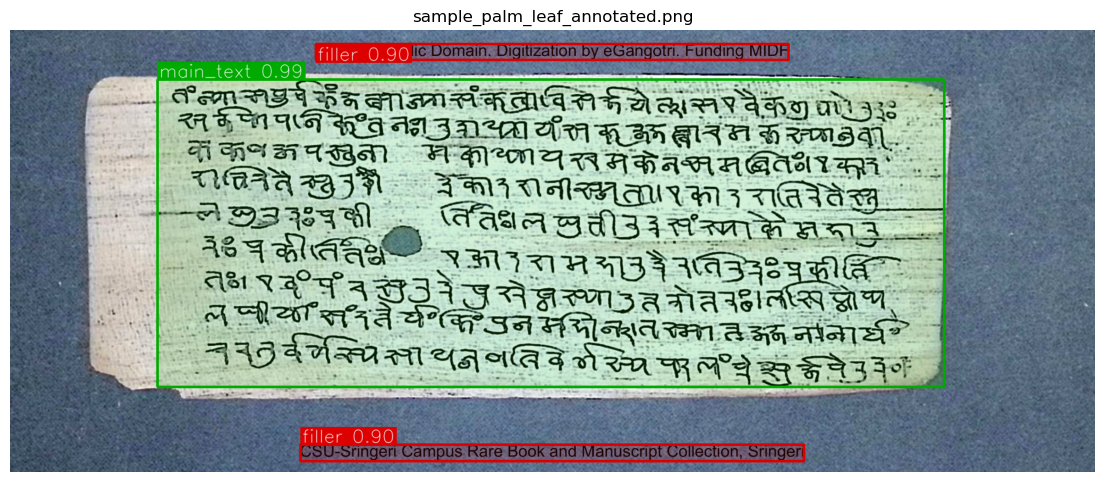

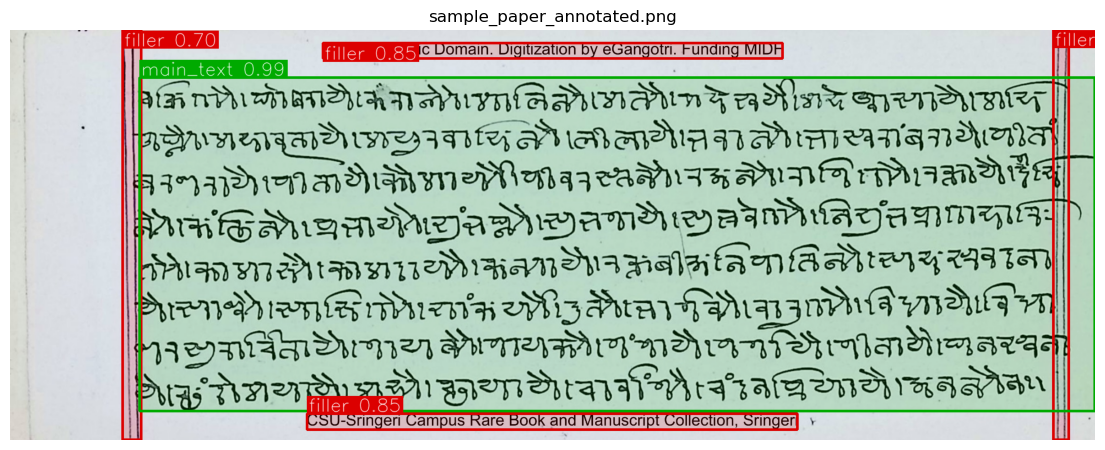

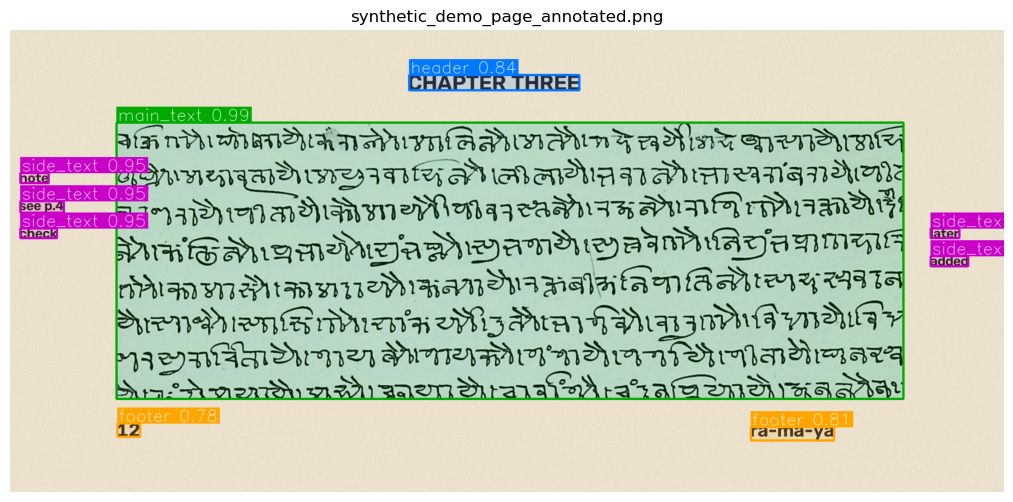

In [65]:
# show every annotated result
for name in sorted(os.listdir("results")):
    if name.endswith("_annotated.png"):
        show(read_image(os.path.join("results", name)), name, size=(14, 6))

## Notes / limitations (being honest)
- It is **rule-based**, so it works best on pages with one main block of writing and clear gaps around headers, footers and notes.
- The confidence value is a score I computed from how clearly each rule fits. It is **not** a probability from a trained model.
- Marginal notes written very close to the main text (closer than about one letter height) will get merged into `main_text`.
- Pencil text and decorations are only caught when they look like small stamp text or long lines. A trained detector (e.g. YOLO) fine-tuned on labelled pages would be the next step.